# LightGBM — issue #21
Mismo protocolo que el resto de modelos: 23 variables (`load_train_test()`),
`build_preprocessor()` dentro del Pipeline, StratifiedKFold(5, shuffle=True, random_state=42),
métrica principal F1 macro y gap train − validación < 0,05.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

from src.preprocessing import build_preprocessor, load_train_test

SEED = 42
X_train, X_test, y_train, y_test = load_train_test()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_pipeline(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])

def evaluate(model):
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=cv,
                            scoring="f1_macro", return_train_score=True)
    train, val = scores["train_score"].mean(), scores["test_score"].mean()
    return {"F1 train": round(train, 3), "F1 val": round(val, 3),
            "std val": round(scores["test_score"].std(), 3), "gap": round(train - val, 3)}

print(X_train.shape)

(10088, 23)


## Referencias: Dummy y LightGBM con parámetros por defecto

In [2]:
results = {
    "Dummy (most_frequent)": evaluate(DummyClassifier(strategy="most_frequent")),
    "LightGBM por defecto": evaluate(LGBMClassifier(random_state=SEED, verbose=-1)),
}
pd.DataFrame(results).T

,F1 train,F1 val,std val,gap
Dummy (most_frequent),0.167,0.167,0.000,0.00
LightGBM por defecto,0.878,0.768,0.003,0.11


## Optuna (solo train)
Optuna maximiza el F1 macro de validación (40 pruebas, TPE con semilla 42) y guarda el gap de cada prueba.
Después se elige la mejor prueba que cumple **gap < 0,05**: preferimos un modelo que no memorice
aunque pierda algo de F1 de validación.

In [3]:
import optuna

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 48),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 150),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
    }
    model = LGBMClassifier(**params, random_state=SEED, verbose=-1, n_jobs=1)
    scores = cross_validate(make_pipeline(model), X_train, y_train, cv=cv,
                            scoring="f1_macro", return_train_score=True, n_jobs=-1)
    train, val = scores["train_score"].mean(), scores["test_score"].mean()
    trial.set_user_attr("F1 train", train)
    trial.set_user_attr("std val", scores["test_score"].std())
    trial.set_user_attr("gap", train - val)
    return val

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=40)

trials = study.trials_dataframe()
trials = trials.rename(columns=lambda c: c.replace("user_attrs_", "").replace("params_", ""))
trials = trials.rename(columns={"value": "F1 val"})
trials[["number", "F1 train", "F1 val", "std val", "gap"]].sort_values("F1 val", ascending=False).head(10).round(3)

/Users/esrakesken/bcn-price-classifier/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,number,F1 train,F1 val,std val,gap
36,36,0.928,0.777,0.003,0.150
26,26,0.911,0.775,0.003,0.136
38,38,0.913,0.775,0.004,0.138
28,28,0.961,0.775,0.006,0.186
30,30,0.928,0.775,0.003,0.154
37,37,0.912,0.775,0.004,0.137
12,12,0.886,0.774,0.004,0.112
34,34,0.952,0.774,0.003,0.178
23,23,0.953,0.774,0.006,0.179
10,10,0.915,0.773,0.007,0.142


In [4]:
GAP_LIMIT = 0.05
valid = trials[trials["gap"] < GAP_LIMIT].sort_values("F1 val", ascending=False)
print(f"Pruebas con gap < {GAP_LIMIT}: {len(valid)} de {len(trials)}")

best = valid.iloc[0]
best_params = study.trials[int(best["number"])].params
display(valid[["number", "F1 train", "F1 val", "std val", "gap"]].head(5).round(3))
best_params

Pruebas con gap < 0.05: 8 de 40


,number,F1 train,F1 val,std val,gap
11,11,0.812,0.763,0.002,0.049
8,8,0.804,0.761,0.003,0.043
1,1,0.801,0.760,0.002,0.041
9,9,0.795,0.757,0.006,0.038
2,2,0.778,0.755,0.003,0.023


{'n_estimators': 150,
 'learning_rate': 0.056922031759422606,
 'num_leaves': 43,
 'max_depth': 6,
 'min_child_samples': 42,
 'subsample': 0.6851781063212045,
 'colsample_bytree': 0.611586992897352,
 'reg_lambda': 2.910164393655262}

## Modelo elegido: métricas por clase (predicciones fuera de fold, solo train)
El test se reserva para la evaluación final del champion (#22).

              precision    recall  f1-score   support

   Económico      0.882     0.881     0.882      3366
       Medio      0.655     0.668     0.662      3359
     Premium      0.752     0.740     0.746      3363

    accuracy                          0.763     10088
   macro avg      0.763     0.763     0.763     10088
weighted avg      0.763     0.763     0.763     10088

Errores extremos (Económico ↔ Premium): 1.0%


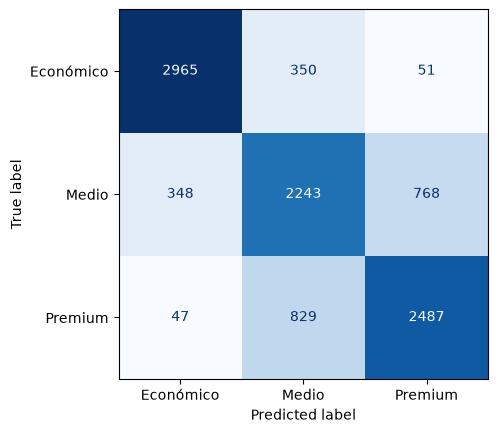

In [5]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

LABELS = ["Económico", "Medio", "Premium"]
final_model = LGBMClassifier(**best_params, subsample_freq=1, random_state=SEED, verbose=-1, n_jobs=1)

oof_pred = cross_val_predict(make_pipeline(final_model), X_train, y_train, cv=cv, n_jobs=-1)
print(classification_report(y_train, oof_pred, labels=LABELS, digits=3))

matrix = confusion_matrix(y_train, oof_pred, labels=LABELS)
ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(cmap="Blues", colorbar=False)

extreme = (matrix[0, 2] + matrix[2, 0]) / matrix.sum()
print(f"Errores extremos (Económico ↔ Premium): {extreme:.1%}")

In [6]:
import time

start = time.perf_counter()
make_pipeline(final_model).fit(X_train, y_train)
fit_seconds = time.perf_counter() - start

summary = pd.DataFrame([{
    "Modelo": "LightGBM (Optuna, gap < 0,05)",
    "Prueba Optuna": int(best["number"]),
    "F1 train": round(best["F1 train"], 3),
    "F1 val": round(best["F1 val"], 3),
    "std val": round(best["std val"], 3),
    "gap": round(best["gap"], 3),
    "F1 Dummy": results["Dummy (most_frequent)"]["F1 val"],
    "Errores extremos": f"{extreme:.1%}",
    "Entrenamiento (s)": round(fit_seconds, 1),
}])
display(summary)
best_params

,Modelo,Prueba Optuna,F1 train,F1 val,std val,gap,F1 Dummy,Errores extremos,Entrenamiento (s)
0,"LightGBM (Optuna, gap < 0,05)",11,0.812,0.763,0.002,0.049,0.167,1.0%,0.4


{'n_estimators': 150,
 'learning_rate': 0.056922031759422606,
 'num_leaves': 43,
 'max_depth': 6,
 'min_child_samples': 42,
 'subsample': 0.6851781063212045,
 'colsample_bytree': 0.611586992897352,
 'reg_lambda': 2.910164393655262}

In [7]:
# Fila para la tabla común (#22): mismas 18 columnas que docs/results/logreg_comparison.csv
import hashlib, json, subprocess, time
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score
from src.preprocessing import RAW_DATA_PATH

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "docs" / "results"
OUT.mkdir(parents=True, exist_ok=True)

# Mismo protocolo que el resto: CV secuencial (n_jobs=1) para que los tiempos sean comparables.
scores = cross_validate(make_pipeline(final_model), X_train, y_train, cv=cv,
                        scoring="f1_macro", return_train_score=True, n_jobs=1)
start = time.perf_counter()
oof_pred = cross_val_predict(make_pipeline(final_model), X_train, y_train, cv=cv, n_jobs=1)
oof_seconds = time.perf_counter() - start
matrix = confusion_matrix(y_train, oof_pred, labels=LABELS)

train_f1, val_f1 = scores["train_score"].mean(), scores["test_score"].mean()
row = {
    "model": "LightGBM",
    "cv_train_f1_macro": train_f1,
    "cv_validation_f1_macro": val_f1,
    "cv_validation_std": scores["test_score"].std(),
    "gap": train_f1 - val_f1,
    "gap_under_005": bool(train_f1 - val_f1 < 0.05),
    "cv_fit_seconds": scores["fit_time"].sum(),
    "evaluation_set": "train_oof",
    "oof_accuracy": accuracy_score(y_train, oof_pred),
    "oof_f1_macro": f1_score(y_train, oof_pred, average="macro"),
    "oof_extreme_error_rate": (matrix[0, 2] + matrix[2, 0]) / len(y_train),
    "oof_seconds": oof_seconds,
    "search_seconds": trials["duration"].dt.total_seconds().sum(),
    "params": json.dumps({**best_params, "subsample_freq": 1}),
    "cv": "StratifiedKFold(5, shuffle=True, random_state=42)",
    "snapshot": "2026-09-17",
    "code_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
    "raw_sha256": hashlib.sha256(RAW_DATA_PATH.read_bytes()).hexdigest(),
}
assert abs(val_f1 - best["F1 val"]) < 1e-9, "La CV debe reproducir la prueba elegida de Optuna"

lightgbm_row = pd.DataFrame([row])
lightgbm_row.to_csv(OUT / "lightgbm_comparison.csv", index=False)
print("Guardado: docs/results/lightgbm_comparison.csv")
lightgbm_row.T

Guardado: docs/results/lightgbm_comparison.csv


,0
model,LightGBM
cv_train_f1_macro,0.812453
cv_validation_f1_macro,0.762985
cv_validation_std,0.001777
gap,0.049467
gap_under_005,True
cv_fit_seconds,1.821358
evaluation_set,train_oof
oof_accuracy,0.762787
oof_f1_macro,0.763016


## Conclusiones
- Con parámetros por defecto LightGBM memoriza: gap ≈ 0,11.
- Si Optuna solo maximiza la validación, el F1 apenas sube (≈ 0,777) pero el gap crece hasta 0,15–0,19:
  memorizar no mejora la validación.
- El modelo elegido (gap < 0,05) obtiene F1 macro de validación ≈ 0,763, solo ~1,4 puntos menos,
  con árboles más prudentes (más ejemplos por hoja, más regularización, menos árboles).
- Medio es la clase más difícil (F1 ≈ 0,66): tiene dos vecinas. Casi todos los errores son entre
  clases vecinas; los errores extremos Económico ↔ Premium son ≈ 1 %.
- Resultados de validación cruzada en train, no una evaluación final. El test se usa en #22.